# Practical 5: Ridge and Lasso Regression (Regularisation)

**Aim:** Use Ridge and Lasso regression and see how they help with overfitting and multicollinearity.

**Dataset:** Diabetes (10 features, some strongly correlated: s1, s2, s3, s4, s5). Built into scikit-learn.

**Steps:** 1) Load, split, scale  2) Part A: compare Linear, Ridge, Lasso  3) Coefficient paths  4) Pick alpha  5) Part B: show overfitting with many features and little data

## Step 1: Load, split and scale

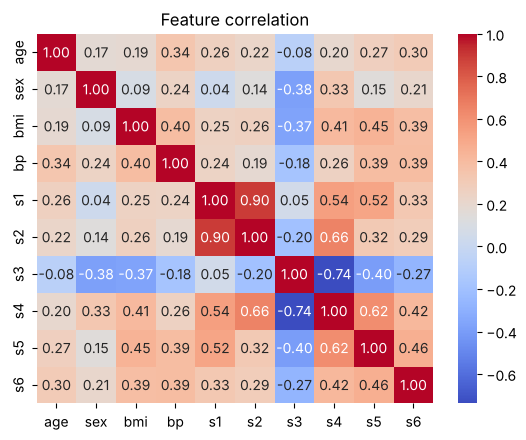

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score

data = load_diabetes()
X = data.data
y = data.target
names = data.feature_names

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Ridge and Lasso need scaled features (the penalty treats all coefficients equally)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# Which features are strongly related to each other?
sns.heatmap(pd.DataFrame(X, columns=names).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature correlation")
plt.show()

**How to read:** `s1` and `s2` are correlated at about 0.9, and `s4`, `s5` are also related to them. These near-copies cause **multicollinearity**, which makes ordinary linear regression unstable.

## Part A: Linear vs Ridge vs Lasso
- **Ridge** adds a penalty on the *squares* of the coefficients (L2): it shrinks them.
- **Lasso** adds a penalty on the *absolute values* (L1): it can shrink some coefficients to **exactly 0** (feature selection).
- `alpha` is the strength of the penalty.

In [2]:
linear = LinearRegression().fit(X_train, y_train)
ridge = Ridge(alpha=10).fit(X_train, y_train)
lasso = Lasso(alpha=2).fit(X_train, y_train)

for name, model in [("Linear", linear), ("Ridge", ridge), ("Lasso", lasso)]:
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    print(name, "| Train R2:", round(train_r2, 3), "| Test R2:", round(test_r2, 3))

print("Features Lasso set to zero:", [n for n, c in zip(names, lasso.coef_) if c == 0])

Linear | Train R2: 0.524 | Test R2: 0.477
Ridge | Train R2: 0.521 | Test R2: 0.478
Lasso | Train R2: 0.514 | Test R2: 0.486
Features Lasso set to zero: ['age', 's2', 's4']


     Linear  Ridge  Lasso
age    1.35   1.67   0.00
sex  -12.45 -11.76  -8.41
bmi   26.21  26.19  26.81
bp    18.61  17.83  16.35
s1   -43.26 -12.26  -2.99
s2    24.26   0.66  -0.00
s3     5.74  -7.76 -13.08
s4    13.96   9.19   0.00
s5    31.58  19.35  17.96
s6     1.98   2.70   1.29


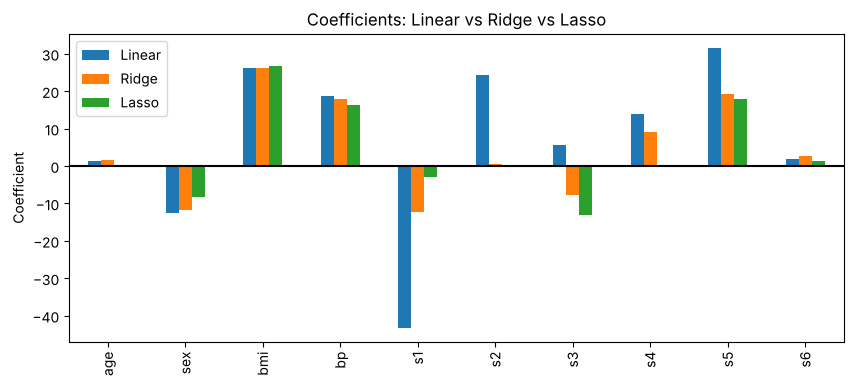

In [3]:
coef = pd.DataFrame({"Linear": linear.coef_, "Ridge": ridge.coef_, "Lasso": lasso.coef_}, index=names)
print(coef.round(2))

coef.plot(kind="bar", figsize=(10, 4))
plt.axhline(0, color="black")
plt.title("Coefficients: Linear vs Ridge vs Lasso")
plt.ylabel("Coefficient")
plt.show()

**How to read:** each group of bars is one feature, the colours are the models.
- **Linear** has the biggest coefficients, and for the related features `s1` and `s2` they are big and opposite in sign (unstable, because of multicollinearity).
- **Ridge** makes all coefficients smaller, and `s1`, `s2` become calm.
- **Lasso** sets some coefficients to **exactly zero**, so those features are dropped.

On this data all three have similar test R² (about 0.48) because there are only 10 features and 300 samples, so overfitting is small. Part B shows the real benefit.

## Coefficient paths: what happens as alpha grows?

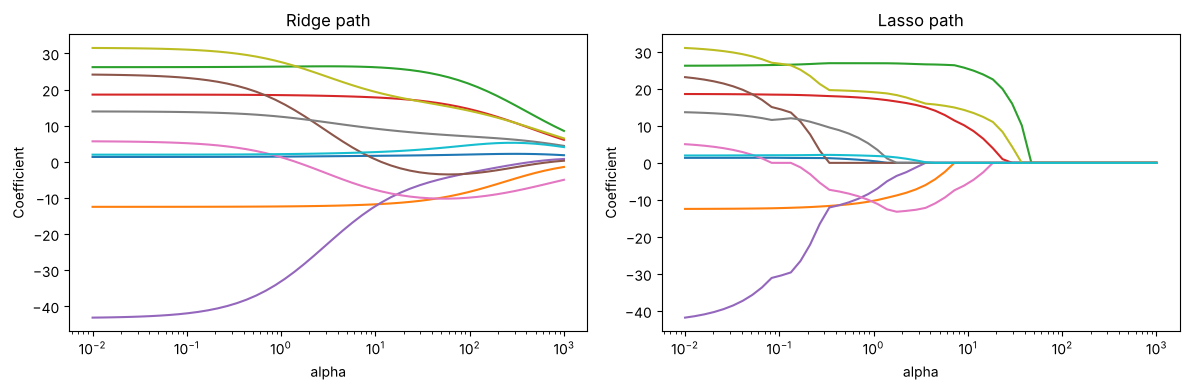

In [4]:
alphas = np.logspace(-2, 3, 50)
ridge_coefs = []
lasso_coefs = []

for a in alphas:
    ridge_coefs.append(Ridge(alpha=a).fit(X_train, y_train).coef_)
    lasso_coefs.append(Lasso(alpha=a, max_iter=10000).fit(X_train, y_train).coef_)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(alphas, ridge_coefs)
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Coefficient")
plt.title("Ridge path")

plt.subplot(1, 2, 2)
plt.plot(alphas, lasso_coefs)
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Coefficient")
plt.title("Lasso path")

plt.tight_layout()
plt.show()

**How to read:** the x-axis is alpha (penalty strength, log scale). Each line is one feature.
- **Ridge path:** all lines shrink **smoothly** towards 0 but never exactly reach it.
- **Lasso path:** lines hit **exactly 0 one by one** and stay there. The features that survive the longest are the most important.

## Choose alpha with cross-validation

In [5]:
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 50)).fit(X_train, y_train)
lasso_cv = LassoCV(cv=5).fit(X_train, y_train)

print("Best Ridge alpha:", round(ridge_cv.alpha_, 3))
print("Best Lasso alpha:", round(lasso_cv.alpha_, 3))

Best Ridge alpha: 25.595
Best Lasso alpha: 0.11


## Part B: Overfitting (many features, few samples)
We turn the 10 features into 65 features (adding squares and products) and train on only 80 samples. Too many features for too few samples makes plain linear regression overfit.

    Model  Train R2  Test R2
0  Linear     0.914  -11.803
1   Ridge     0.590    0.298
2   Lasso     0.688    0.230


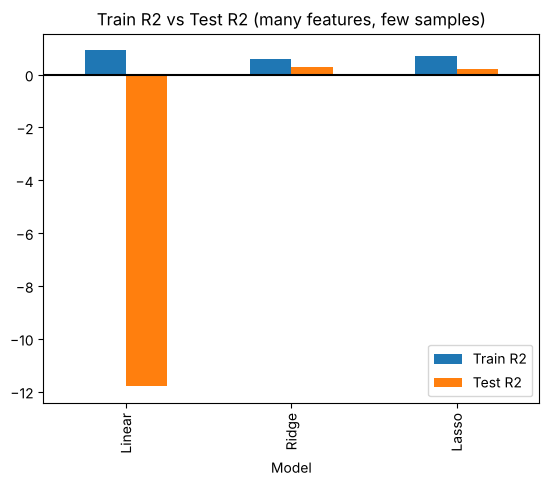

In [6]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_small = poly.fit_transform(X_train_raw[:80])      # only 80 training samples, 65 features
X_big_test = poly.transform(X_test_raw)
y_small = y_train[:80]

scaler2 = StandardScaler()
X_small = scaler2.fit_transform(X_small)
X_big_test = scaler2.transform(X_big_test)

linear_b = LinearRegression().fit(X_small, y_small)
ridge_b = Ridge(alpha=100).fit(X_small, y_small)
lasso_b = Lasso(alpha=3, max_iter=10000).fit(X_small, y_small)

names_b = ["Linear", "Ridge", "Lasso"]
train_scores = []
test_scores = []
for m in [linear_b, ridge_b, lasso_b]:
    train_scores.append(round(m.score(X_small, y_small), 3))
    test_scores.append(round(m.score(X_big_test, y_test), 3))

result = pd.DataFrame({"Model": names_b, "Train R2": train_scores, "Test R2": test_scores})
print(result)

result.set_index("Model").plot(kind="bar")
plt.axhline(0, color="black")
plt.title("Train R2 vs Test R2 (many features, few samples)")
plt.show()

**How to read:** compare the blue (train) and orange (test) bars.
- **Linear:** train R² is very high but test R² is **negative** (worse than just predicting the average). It memorised the training data: **overfitting**.
- **Ridge and Lasso:** train R² is lower but test R² is much better, and the gap is smaller. Regularisation traded a little accuracy on training data for much better results on new data.

## Error vs alpha (Ridge)

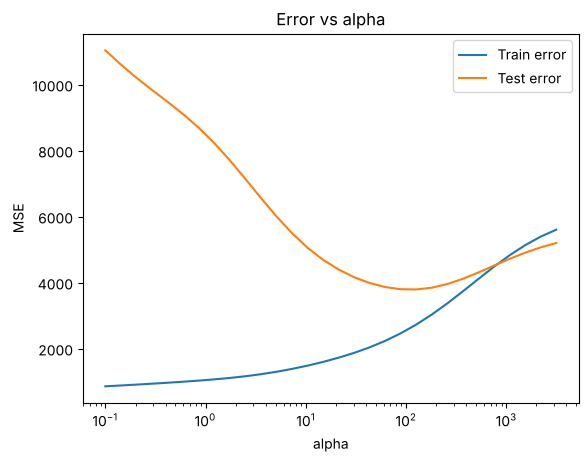

In [7]:
alpha_list = np.logspace(-1, 3.5, 30)
train_err = []
test_err = []

for a in alpha_list:
    m = Ridge(alpha=a).fit(X_small, y_small)
    train_err.append(mean_squared_error(y_small, m.predict(X_small)))
    test_err.append(mean_squared_error(y_test, m.predict(X_big_test)))

plt.plot(alpha_list, train_err, label="Train error")
plt.plot(alpha_list, test_err, label="Test error")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("MSE")
plt.title("Error vs alpha")
plt.legend()
plt.show()

**How to read:** small alpha (left): train error is very low but test error is high = **overfitting**. Large alpha (right): both errors are high = **underfitting**. The lowest point of the test curve is the best alpha.

## Conclusion
Ridge shrinks coefficients and stabilises correlated features. Lasso also sets some coefficients to zero (feature selection). With many features and little data, plain linear regression overfits badly while Ridge and Lasso keep the test error much lower. The best alpha is found by cross-validation.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is regularisation and why use it?**
Adding a penalty on the size of the coefficients to the loss function. It prevents overfitting, stabilises models with multicollinearity and (Lasso) performs feature selection.

**Q2. What is Ridge regression (L2)?**
Linear regression with a penalty of alpha times the sum of squared coefficients: $\min \sum(y_i-\hat{y}_i)^2 + \alpha\sum\beta_j^2$. It shrinks coefficients but does not make them exactly zero.

**Q3. What is Lasso regression (L1)?**
Linear regression with a penalty of alpha times the sum of absolute coefficients: $\min \sum(y_i-\hat{y}_i)^2 + \alpha\sum|\beta_j|$. It can shrink some coefficients exactly to zero, so it also selects features.

**Q4. Difference between Ridge and Lasso?**
Ridge uses L2 and keeps all features with smaller weights; best when all features matter and are correlated. Lasso uses L1 and removes features; best when many features are irrelevant (sparse models).

**Q5. Why does Lasso give exact zeros but Ridge does not?**
The L1 constraint region is a diamond with corners on the axes, so the loss contours often touch at a corner where a coefficient is zero. The L2 region is a circle with no corners, so exact zeros are rare.

**Q6. What does alpha (lambda) control?**
The strength of the penalty. Alpha = 0 gives ordinary linear regression. Larger alpha means stronger shrinkage, higher bias and lower variance. Too large leads to underfitting.

**Q7. How do you choose alpha?**
By cross-validation (`RidgeCV`, `LassoCV`, `GridSearchCV`), choosing the alpha with the lowest validation error.

**Q8. What is multicollinearity?**
High correlation between independent variables, which makes coefficient estimates unreliable (large, unstable, sign-flipping). Detect it with the correlation matrix or VIF.

**Q9. How does Ridge handle multicollinearity?**
With correlated features, OLS coefficients become huge and unstable. The L2 penalty spreads weight across correlated features and stabilises the solution; it also makes $X^TX + \alpha I$ always invertible.

**Q10. How does Lasso behave with correlated features?**
It tends to pick one of them and set the others to zero, and the choice can be arbitrary and change between samples.

**Q11. What is Elastic Net?**
A combination of L1 and L2 penalties, useful when features are correlated and you also want sparsity.

**Q12. Why scale data before Ridge or Lasso?**
The penalty treats all coefficients equally, so features with large scales would be penalised unfairly. Standardising makes the penalty fair.

**Q13. Is the intercept penalised?**
No, only the feature coefficients are.

**Q14. Effect of regularisation on bias and variance?**
It increases bias slightly and decreases variance, which usually lowers test error when the model was overfitting.

**Q15. When would you not use regularisation?**
When the model already underfits, or when there are few features and plenty of data.

**Q16. Is Lasso a feature selection method?**
Yes, an embedded one, because selection happens during training.

**Q17. What is overfitting and how did you see it in this practical?**
When a model fits training data too closely and performs poorly on new data. In Part B, OLS had a high training R² but a low test R².

**Q18. What happens when alpha = 0? When alpha is very large?**
Alpha = 0 is plain OLS. A very large alpha pushes all coefficients to (nearly) zero, so the model predicts roughly the mean (underfitting).

**Q19. Does regularisation always improve test accuracy?**
No. If the model is not overfitting (as in Part A on 10 features), the improvement is small or none. It helps most with many features, few samples or collinearity.

**Q20. What is the VIF?**
Variance Inflation Factor: $1/(1-R_j^2)$, where $R_j^2$ comes from regressing feature j on the others. Values above 5 to 10 indicate problematic collinearity.

**Q21. Closed-form solution of Ridge?**
$\beta = (X^TX + \alpha I)^{-1}X^Ty$. Lasso has no closed form and is solved with coordinate descent.

**Q22. Does Ridge perform feature selection?**
No. It keeps all features.

## B. Questions about the graphs

**G1. Explain the coefficient bar plot.**
Each group of bars is one feature; the colours are the models. OLS has the largest coefficients (large with opposite signs for correlated features `s1` and `s2`). Ridge bars are smaller. Lasso has some bars exactly at zero, so those features are removed.

**G2. Explain the Ridge coefficient path.**
X-axis: alpha (log). Y-axis: coefficient values. At small alpha the coefficients equal the OLS values. As alpha grows, all coefficients shrink smoothly toward zero but never exactly reach it.

**G3. Explain the Lasso coefficient path.**
As alpha grows, coefficients hit exactly zero one at a time and stay there. The last features to reach zero are the most important ones.

**G4. What does the validation curve (error vs alpha) show?**
Train and test error versus alpha. Tiny alpha gives overfitting (low train error, high test error); huge alpha gives underfitting (both high); the minimum of the test curve is the best alpha.

**G5. What does the gap between train and test R² show?**
A large gap means overfitting. Regularisation shrinks the gap.

**G8. What does the correlation heatmap show?**
Which features are strongly correlated (for example `s1` and `s2` at about 0.9), indicating multicollinearity.

## C. Code questions

**C1. What is the difference between `Ridge(alpha=10)` and `RidgeCV`?**
`Ridge` uses a fixed alpha. `RidgeCV` tries many alphas by cross-validation and keeps the best.

**C2. Why `max_iter` in Lasso?**
Lasso is solved iteratively (coordinate descent); more iterations may be needed to converge.

**C3. Why `np.logspace` for alphas?**
The effect of alpha changes over orders of magnitude, so a logarithmic grid covers the range efficiently.

**C5. How do you get the features Lasso kept?**
Those where `model.coef_` is not zero.